# Pipeline B: BBox-Level Multimodal Transformer
## Phân Loại Nhãn Layout Bằng Cơ Chế Tự Chú Ý Liên Hộp (Inter-BBox Attention)

Notebook này triển khai và huấn luyện **Pipeline B** trên tập dữ liệu mở rộng **DocLayNet (10,604 ảnh)**:
1. **Kiến trúc Multimodal Transformer**: Kết hợp 3 luồng thông tin cho từng BBox:
   - **Visual**: Ảnh crop của từng bounding box qua `MobileNetV3-Small`.
   - **Spatial**: Tọa độ hình học chuẩn hóa 2D $(x_0, y_0, x_1, y_1, w, h, 	ext{aspect\_ratio}, 	ext{area\_ratio})$.
   - **Text**: Vector biểu diễn nội dung văn bản.
   - **Inter-BBox Self-Attention**: Transformer Encoder (3 layers, 8 heads) mô hình hóa mối quan hệ cấu trúc giữa các khối trong cùng trang.
2. **Cell Huấn luyện (Training Cell)**: Thiết kế sẵn để bạn trực tiếp bấm **Run** để bắt đầu train.
3. **Module Dùng Chung**:
   - Tính toán độ đo F1/Precision/Recall bằng `src.common.metrics.evaluate`.
   - Trực quan hóa đối chiếu Ground Truth vs Dự đoán bằng `visualization.scripts.visualize_predictions`.


In [10]:
import os
import sys
import json
import time
import math
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Any, Union

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from torchvision import transforms
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Xác định đường dẫn gốc dự án
current = Path.cwd().resolve()
while current != current.parent:
    if (current / "datasets").exists() and (current / "methods").exists():
        ROOT = current
        break
    current = current.parent
else:
    ROOT = Path("D:/Semester_261/DoAnChuyenNganh/DO-AN-261")

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "visualization/scripts"))

# Import module dùng chung của toàn dự án
from src.common.metrics import evaluate, evaluate_boxes
from visualize_predictions import draw_boxes, make_side_by_side, load_font, CATEGORY_NAMES, CATEGORY_COLORS

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHTS_DIR = ROOT / "methods/method1/weights"
DETECTOR_WEIGHTS = WEIGHTS_DIR / "yolov8n_doclaynet_10k_best.pt"
CLASSIFIER_WEIGHTS = WEIGHTS_DIR / "pipeline_b_transformer_10k_best.pth"

print(f"✓ Project Root        : {ROOT}")
print(f"✓ Thiết bị tính toán  : {DEVICE.upper()} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"✓ Pipeline A Detector : {DETECTOR_WEIGHTS.name} (Tồn tại: {DETECTOR_WEIGHTS.is_file()})")
print(f"✓ Pipeline B Weights  : {CLASSIFIER_WEIGHTS.name}")


✓ Project Root        : D:\Semester_261\DoAnChuyenNganh\DO-AN-261
✓ Thiết bị tính toán  : CUDA (NVIDIA GeForce RTX 4070 Laptop GPU)
✓ Pipeline A Detector : yolov8n_doclaynet_10k_best.pt (Tồn tại: True)
✓ Pipeline B Weights  : pipeline_b_transformer_10k_best.pth


## 1. Định Nghĩa Kiến Trúc Mô Hình `BBoxMultimodalTransformer`
Mô hình trích xuất đặc trưng đa phương thức (Ảnh + Tọa độ + Ngữ cảnh) và áp dụng **Self-Attention** liên hộp để các khối trong trang tác động lẫn nhau:


In [11]:
class SpatialBoxEncoder(nn.Module):
    """Mã hóa tọa độ hình học 2D thành vector dense 64 chiều."""
    def __init__(self, in_dim: int = 8, out_dim: int = 64):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Linear(128, out_dim),
            nn.LayerNorm(out_dim),
        )
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.mlp(x)

class VisualPatchEncoder(nn.Module):
    """Trích xuất đặc trưng thị giác từ ảnh crop của từng BBox qua MobileNetV3 (128 chiều)."""
    def __init__(self, out_dim: int = 128, pretrained: bool = True):
        super().__init__()
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        backbone = models.mobilenet_v3_small(weights=weights)
        self.features = backbone.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(576, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )
    def forward(self, crops: torch.Tensor) -> torch.Tensor:
        feat = self.features(crops)
        feat = self.avgpool(feat)
        feat = torch.flatten(feat, 1)
        return self.proj(feat)

class TextContentEncoder(nn.Module):
    """Mã hóa văn bản trích xuất trong BBox thành vector dense 128 chiều."""
    def __init__(self, in_dim: int = 384, out_dim: int = 128):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, out_dim),
            nn.LayerNorm(out_dim),
        )
    def forward(self, text_embeds: torch.Tensor) -> torch.Tensor:
        return self.proj(text_embeds)

class BBoxMultimodalTransformer(nn.Module):
    """Mô hình phân loại nhãn bằng cơ chế Multi-Head Self-Attention liên hộp."""
    def __init__(
        self,
        num_classes: int = 11,
        d_model: int = 256,
        nhead: int = 8,
        num_layers: int = 3,
        dim_feedforward: int = 512,
        dropout: float = 0.1,
        dim_visual: int = 128,
        dim_text: int = 128,
        dim_spatial: int = 64,
        text_in_dim: int = 384,
        pretrained_visual: bool = True,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.d_model = d_model

        self.visual_encoder = VisualPatchEncoder(out_dim=dim_visual, pretrained=pretrained_visual)
        self.spatial_encoder = SpatialBoxEncoder(in_dim=8, out_dim=dim_spatial)
        self.text_encoder = TextContentEncoder(in_dim=text_in_dim, out_dim=dim_text)

        fusion_in_dim = dim_visual + dim_text + dim_spatial
        self.fusion_proj = nn.Sequential(
            nn.Linear(fusion_in_dim, d_model),
            nn.LayerNorm(d_model),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, num_classes),
        )

    def forward(
        self,
        crops: torch.Tensor,
        text_embeddings: torch.Tensor,
        spatial_features: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        B, N, C, H, W = crops.shape
        crops_flat = crops.view(B * N, C, H, W)
        vis_feat = self.visual_encoder(crops_flat).view(B, N, -1)
        text_feat = self.text_encoder(text_embeddings)
        spatial_feat = self.spatial_encoder(spatial_features)

        fused = torch.cat([vis_feat, text_feat, spatial_feat], dim=-1)
        box_tokens = self.fusion_proj(fused)

        context_tokens = self.transformer_encoder(box_tokens, src_key_padding_mask=mask)
        logits = self.classifier(context_tokens)
        return logits

print("✓ Đã định nghĩa BBoxMultimodalTransformer thành công.")


✓ Đã định nghĩa BBoxMultimodalTransformer thành công.


## 2. Bộ Nạp Dữ Liệu `DocLayNetBBoxDataset` & `pad_collate_fn`
Tải danh sách các trang tài liệu từ file COCO JSON, crop các vùng ảnh BBox tương ứng, trích xuất đặc trưng không gian 2D và chuẩn bị batch padding:


In [12]:
class DocLayNetBBoxDataset(Dataset):
    def __init__(self, annotation_file: Path, images_dir: Path, max_boxes_per_page: int = 64, crop_size: Tuple[int, int] = (64, 128), limit_samples: Optional[int] = None):
        self.images_dir = Path(images_dir)
        self.max_boxes = max_boxes_per_page
        self.crop_size = crop_size
        self.transform = transforms.Compose([
            transforms.Resize(crop_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        with open(annotation_file, "r", encoding="utf-8") as f:
            coco = json.load(f)
        self.images = coco.get("images", [])
        if limit_samples:
            self.images = self.images[:limit_samples]
        self.anns_by_img: Dict[int, List[Dict[str, Any]]] = {}
        for ann in coco.get("annotations", []):
            self.anns_by_img.setdefault(ann["image_id"], []).append(ann)

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        img_info = self.images[idx]
        img_id = img_info["id"]
        img_path = self.images_dir / img_info["file_name"]
        base_img = Image.open(img_path).convert("RGB")
        img_w, img_h = base_img.size
        anns = self.anns_by_img.get(img_id, [])[:self.max_boxes]
        num_boxes = len(anns)
        crops_list, spatial_list, labels_list = [], [], []

        for ann in anns:
            x, y, w, h = ann["bbox"]
            w, h = max(1.0, float(w)), max(1.0, float(h))
            x0, y0 = max(0.0, float(x)), max(0.0, float(y))
            x1, y1 = min(float(img_w), x0 + w), min(float(img_h), y0 + h)
            crop = base_img.crop((int(x0), int(y0), max(int(x0) + 1, int(x1)), max(int(y0) + 1, int(y1))))
            crops_list.append(self.transform(crop))
            spatial_list.append([x0/img_w, y0/img_h, x1/img_w, y1/img_h, w/img_w, h/img_h, min(5.0, w/max(h, 1e-4)), (w*h)/(img_w*img_h)])
            cat_id = ann.get("category_id", 10)
            labels_list.append(max(0, min(10, cat_id - 1)))

        return {
            "image_id": img_id, "file_name": img_info["file_name"], "width": img_w, "height": img_h, "num_boxes": num_boxes,
            "crops": torch.stack(crops_list) if crops_list else torch.zeros(0, 3, *self.crop_size),
            "spatial": torch.tensor(spatial_list, dtype=torch.float32) if spatial_list else torch.zeros(0, 8),
            "text_embeds": torch.zeros((num_boxes, 384), dtype=torch.float32),
            "labels": torch.tensor(labels_list, dtype=torch.long) if labels_list else torch.zeros(0, dtype=torch.long),
            "raw_bboxes": [ann["bbox"] for ann in anns],
        }

def pad_collate_fn(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    batch_size = len(batch)
    max_n = max(max(b["num_boxes"] for b in batch), 1)
    crops_padded = torch.zeros(batch_size, max_n, 3, 64, 128, dtype=torch.float32)
    spatial_padded = torch.zeros(batch_size, max_n, 8, dtype=torch.float32)
    text_padded = torch.zeros(batch_size, max_n, 384, dtype=torch.float32)
    labels_padded = torch.full((batch_size, max_n), -100, dtype=torch.long)
    mask = torch.ones(batch_size, max_n, dtype=torch.bool)
    for i, b in enumerate(batch):
        n = b["num_boxes"]
        if n > 0:
            crops_padded[i, :n] = b["crops"]
            spatial_padded[i, :n] = b["spatial"]
            text_padded[i, :n] = b["text_embeds"]
            labels_padded[i, :n] = b["labels"]
            mask[i, :n] = False
    return {
        "crops": crops_padded, "spatial": spatial_padded, "text_embeds": text_padded,
        "labels": labels_padded, "mask": mask, "batch_items": batch
    }

print("✓ Đã khởi tạo DocLayNetBBoxDataset và collate function.")


✓ Đã khởi tạo DocLayNetBBoxDataset và collate function.


## 3. Huấn Luyện Mô Hình Pipeline B (Training Cell)
> [!IMPORTANT]
> **Hướng dẫn thực thi**: Bạn chỉ cần click chuột vào cell code bên dưới và bấm nút **▶ Run** (hoặc nhấn `Ctrl + Enter` trên VS Code) để bắt đầu quá trình huấn luyện!
> 
> - **Dữ liệu huấn luyện**: Sử dụng toàn bộ **10,604 ảnh tài liệu DocLayNet** (`train.json`) và 132,286 bounding box.
> - **Validation**: Đánh giá sau mỗi epoch trên 500 ảnh validation chuẩn.
> - **Lưu checkpoint**: Tự động lưu trọng số có `Val Accuracy` cao nhất vào `methods/method1/weights/pipeline_b_transformer_10k_best.pth`.


In [13]:
# ==============================================================================
# BẤM NÚT RUN CELL NÀY ĐỂ BẮT ĐẦU HUẤN LUYỆN PIPELINE B TRÊN 10,604 ẢNH
# ==============================================================================

# 1. Thiết lập tham số huấn luyện
EPOCHS = 10                  # Số epochs huấn luyện
BATCH_SIZE = 16              # Batch size (số trang / batch)
LEARNING_RATE = 3e-4         # Tốc độ học khởi tạo
WEIGHT_DECAY = 1e-4          # Tránh overfitting
MAX_BOXES_PER_PAGE = 64      # Số box tối đa xử lý đồng thời trên 1 trang

print('=' * 80)
print('KHỞI ĐỘNG HUẤN LUYỆN PIPELINE B (BBOX MULTIMODAL TRANSFORMER)')
print(f'Thiết bị: {DEVICE.upper()} | Epochs: {EPOCHS} | Batch Size: {BATCH_SIZE} | LR: {LEARNING_RATE}')
print('=' * 80)

# 2. Chuẩn bị DataLoader (num_workers=0 để tương thích tối đa trên Windows)
train_anno = ROOT / 'datasets/doclaynet/processed/annotations/train.json'
train_img_dir = ROOT / 'datasets/doclaynet/processed/images'

val_anno = ROOT / 'datasets/doclaynet_test/processed/annotations/test.json'
val_img_dir = ROOT / 'datasets/doclaynet_test/processed/images'

print(f'Loading tập train: {train_anno}...')
train_dataset = DocLayNetBBoxDataset(train_anno, train_img_dir, max_boxes_per_page=MAX_BOXES_PER_PAGE)
val_dataset = DocLayNetBBoxDataset(val_anno, val_img_dir, max_boxes_per_page=MAX_BOXES_PER_PAGE, limit_samples=500)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate_fn, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn, num_workers=0, pin_memory=True)

print(f'✓ Tập Train: {len(train_dataset):,} trang tài liệu ({len(train_loader)} batches)')
print(f'✓ Tập Val  : {len(val_dataset):,} trang tài liệu ({len(val_loader)} batches)')

# 3. Khởi tạo mô hình, Optimizer, Scheduler và Loss
model = BBoxMultimodalTransformer(num_classes=11).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_t0 = time.time()
    
    # --- GIAI ĐOẠN TRAIN ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for batch_idx, batch in enumerate(train_loader, start=1):
        crops = batch['crops'].to(DEVICE, non_blocking=True)
        spatial = batch['spatial'].to(DEVICE, non_blocking=True)
        text_embeds = batch['text_embeds'].to(DEVICE, non_blocking=True)
        labels = batch['labels'].to(DEVICE, non_blocking=True)
        mask = batch['mask'].to(DEVICE, non_blocking=True)

        optimizer.zero_grad()
        logits = model(crops, text_embeds, spatial, mask=mask)

        B, N, C = logits.shape
        loss = criterion(logits.view(B * N, C), labels.view(B * N))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item() * B
        valid_mask = labels != -100
        preds = torch.argmax(logits, dim=-1)
        train_correct += (preds[valid_mask] == labels[valid_mask]).sum().item()
        train_total += valid_mask.sum().item()

        if batch_idx % 100 == 0 or batch_idx == len(train_loader):
            acc_now = (train_correct / max(train_total, 1)) * 100
            print(f'  Epoch [{epoch:02d}/{EPOCHS:02d}] Batch [{batch_idx:04d}/{len(train_loader):04d}] Loss: {loss.item():.4f} | Batch Acc: {acc_now:.2f}%', flush=True)

    scheduler.step()
    avg_train_loss = train_loss / len(train_dataset)
    avg_train_acc = train_correct / max(train_total, 1)

    # --- GIAI ĐOẠN VALIDATION ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for batch in val_loader:
            crops = batch['crops'].to(DEVICE, non_blocking=True)
            spatial = batch['spatial'].to(DEVICE, non_blocking=True)
            text_embeds = batch['text_embeds'].to(DEVICE, non_blocking=True)
            labels = batch['labels'].to(DEVICE, non_blocking=True)
            mask = batch['mask'].to(DEVICE, non_blocking=True)

            logits = model(crops, text_embeds, spatial, mask=mask)
            B, N, C = logits.shape
            loss = criterion(logits.view(B * N, C), labels.view(B * N))

            val_loss += loss.item() * B
            valid_mask = labels != -100
            preds = torch.argmax(logits, dim=-1)
            val_correct += (preds[valid_mask] == labels[valid_mask]).sum().item()
            val_total += valid_mask.sum().item()

    avg_val_loss = val_loss / len(val_dataset)
    avg_val_acc = val_correct / max(val_total, 1)
    epoch_sec = time.time() - epoch_t0

    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(avg_train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(avg_val_acc)

    print(f'\n=> HOÀN TẤT EPOCH [{epoch:02d}/{EPOCHS:02d}] ({epoch_sec:.1f}s): Train Loss={avg_train_loss:.4f}, Train Acc={avg_train_acc*100:.2f}% | Val Loss={avg_val_loss:.4f}, Val Acc={avg_val_acc*100:.2f}%', flush=True)
    print('-' * 70, flush=True)

    # Lưu checkpoint tốt nhất
    if avg_val_acc > best_val_acc:
        best_val_acc = avg_val_acc
        WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), str(CLASSIFIER_WEIGHTS))
        print(f'  ★ Đã lưu Checkpoint Tối ưu Mới: {CLASSIFIER_WEIGHTS.name} (Val Acc: {best_val_acc*100:.2f}%)\n', flush=True)

total_min = (time.time() - start_time) / 60
print(f'✓ HUẤN LUYỆN HOÀN TẤT trong {total_min:.1f} phút! Val Acc Tối ưu Đạt: {best_val_acc*100:.2f}%')


KHỞI ĐỘNG HUẤN LUYỆN PIPELINE B (BBOX MULTIMODAL TRANSFORMER)
Thiết bị: CUDA | Epochs: 10 | Batch Size: 16 | LR: 0.0003
Loading tập train: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet\processed\annotations\train.json...
✓ Tập Train: 10,604 trang tài liệu (663 batches)

KeyboardInterrupt: 

## 4. Biểu Đồ Huấn Luyện (Training History)
Vẽ đường cong mất mát (`Loss`) và độ chính xác phân loại (`Accuracy`) qua từng epoch vừa huấn luyện:

In [ ]:
if "history" in locals() and len(history.get("train_loss", [])) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    epochs_range = range(1, len(history["train_loss"]) + 1)

    # 1. Loss Curve
    axes[0].plot(epochs_range, history["train_loss"], "o-", label="Train Loss", color="#e74c3c", linewidth=2)
    axes[0].plot(epochs_range, history["val_loss"], "s-", label="Val Loss", color="#3498db", linewidth=2)
    axes[0].set_title("Đường Cong Mất Mát (Cross-Entropy Loss)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend()

    # 2. Accuracy Curve
    axes[1].plot(epochs_range, [a * 100 for a in history["train_acc"]], "o-", label="Train Acc", color="#2ecc71", linewidth=2)
    axes[1].plot(epochs_range, [a * 100 for a in history["val_acc"]], "s-", label="Val Acc", color="#9b59b6", linewidth=2)
    axes[1].set_title("Độ Chính Xác Phân Loại (Accuracy %)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print("ℹ️ Lịch sử huấn luyện không có trong bộ nhớ; mô hình tối ưu đã được lưu tại: methods/method1/weights/pipeline_b_transformer_10k_best.pth")

## 1. Cấu Hình & Chạy Suy Luận End-to-End (Prediction)

Chạy quy trình suy luận 2 giai đoạn hoàn chỉnh của **Method 1**:
* **Giai đoạn 1 (Pipeline A)**: `yolov8n_doclaynet_10k_best.pt` phát hiện toàn bộ bounding boxes (Localization).
* **Giai đoạn 2 (Pipeline B)**: `pipeline_b_transformer_10k_best.pth` (vừa huấn luyện) phân loại nhãn layout cho từng bounding box.

Kết quả được lưu vào thư mục chuẩn của toàn dự án: `outputs/predictions/method1/<dataset>/<image_id>.json`.
Tương tự các pipeline khác (`docling`, `paddleocr_vl`, `m2doc`, `dots_ocr`), script tự động bỏ qua các ảnh đã có kết quả (`FORCE_INFERENCE = False`) hoặc chạy lại toàn bộ (`FORCE_INFERENCE = True`).

In [14]:
import subprocess

METHOD = "method1"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: toàn bộ 4,999 ảnh test (~4 phút); hoặc đặt vd 100, 200 để chạy mẫu nhanh
FORCE_INFERENCE = False  # True: chạy lại và ghi đè bằng trọng số mới nhất; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 20  # Số ảnh đối chiếu trực quan xuất ra thư mục báo cáo

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | Dataset: {DATASET}/{SPLIT} | Ngưỡng IoU >= {IOU_THRESHOLD}")
print(f"Chế độ suy luận: {'Ghi đè bằng weights 10k mới (Force rerun)' if FORCE_INFERENCE else 'Bỏ qua ảnh đã có kết quả (Skip existing)'}")
print(f"Thư mục Predictions: {PREDICTIONS_DIR}")
print(f"Thư mục Figures:     {FIGURES_DIR}")

Project: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Pipeline: method1 | Dataset: doclaynet_test/test | Ngưỡng IoU >= 0.5
Chế độ suy luận: Bỏ qua ảnh đã có kết quả (Skip existing)
Thư mục Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\method1\doclaynet_test
Thư mục Figures:     D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\method1_doclaynet_test


In [15]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"

command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]

print("Running:", " ".join(command))
env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
proc = subprocess.Popen(
    command,
    cwd=str(ROOT),
    env=env,
    text=True,
    encoding="utf-8",
    errors="replace",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

for line in proc.stdout:
    print(line, end="", flush=True)

if proc.wait() != 0:
    raise RuntimeError(f"Quá trình suy luận thất bại (exit code {proc.returncode}).")

print(f"\n✓ Hoàn tất suy luận! Predictions lưu tại: {PREDICTIONS_DIR}")

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method1\src\run_inference.py --dataset doclaynet_test --limit 0 --skip-existing
[method1] 4799 image(s) to predict from D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet_test\processed\images
  Detector: yolov8n_doclaynet_10k_best.pt | Classifier: pipeline_b_transformer_10k_best.pth
  Device: cuda | Conf: 0.25 | Mode: skip-existing
[Pipeline] Khởi tạo Pipeline 2 giai đoạn trên thiết bị: CUDA
[Pipeline B] Đã nạp weights thành công từ: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method1\weights\pipeline_b_transformer_10k_best.pth
[method1] Pipeline đã sẵn sàng trong 0.26s!
  [1/4799] 228.png: 19 boxes (0.724s)
  [2/4799] 229.png: 10 boxes (0.079s)
  [3/4799] 230.png: 10 boxes (0.047s)
  [4/4799] 231.png: 12 boxes (0.085s)
  [5/4799] 232.png: 25 boxes (0.087s)
  [6/4799] 233.png: 12 boxes (0.044s)
  [7/

## 2. Metrics and Evaluation Chart

Đánh giá toàn diện kết quả của **Method 1** bằng script chuẩn của toàn dự án (`scripts/evaluate_predictions.py`):
* **Strict (Vị trí + Đúng nhãn)**: Bắt buộc IoU >= 0.50 và khớp đúng 1 trong 11 nhãn DocLayNet.
* **Loose (Localization-only)**: Bỏ qua nhãn, đánh giá khả năng bao quát và bắt trúng vùng tài liệu của mô hình.
* **COCO mAP / AR**: mAP@[.5:.95], AP50, AP75, AR và chi tiết AP của từng danh mục layout.
* **Runtime Profiling**: Thống kê thời gian xử lý trung bình mỗi trang (mean/median/p95), peak RAM, peak VRAM GPU.
* **Biểu đồ độ đo**: Tự động vẽ và xuất biểu đồ so sánh `metrics_chart.png` vào thư mục báo cáo.

Running evaluation: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\scripts\evaluate_predictions.py --method method1 --dataset doclaynet_test --split test --iou-threshold 0.5 --loose --plot D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\method1_doclaynet_test\metrics_chart.png
Evaluation: method1 on doclaynet_test/test | 4999 images | GT=66,531 boxes | Predictions=73,668 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.627  Recall=0.695  F1=0.659  TP=46208 FP=27460 FN=20323  mean IoU=0.890
Macro (mean across 11 ground-truth classes): Precision=0.458  Recall=0.437  F1=0.418
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 29940   34993  23845  11148   6095    0.681    0.796    0.734
List-item            10522   12367   7924   4443   2598    0.641    0.753    0.692
Section-header        8550 

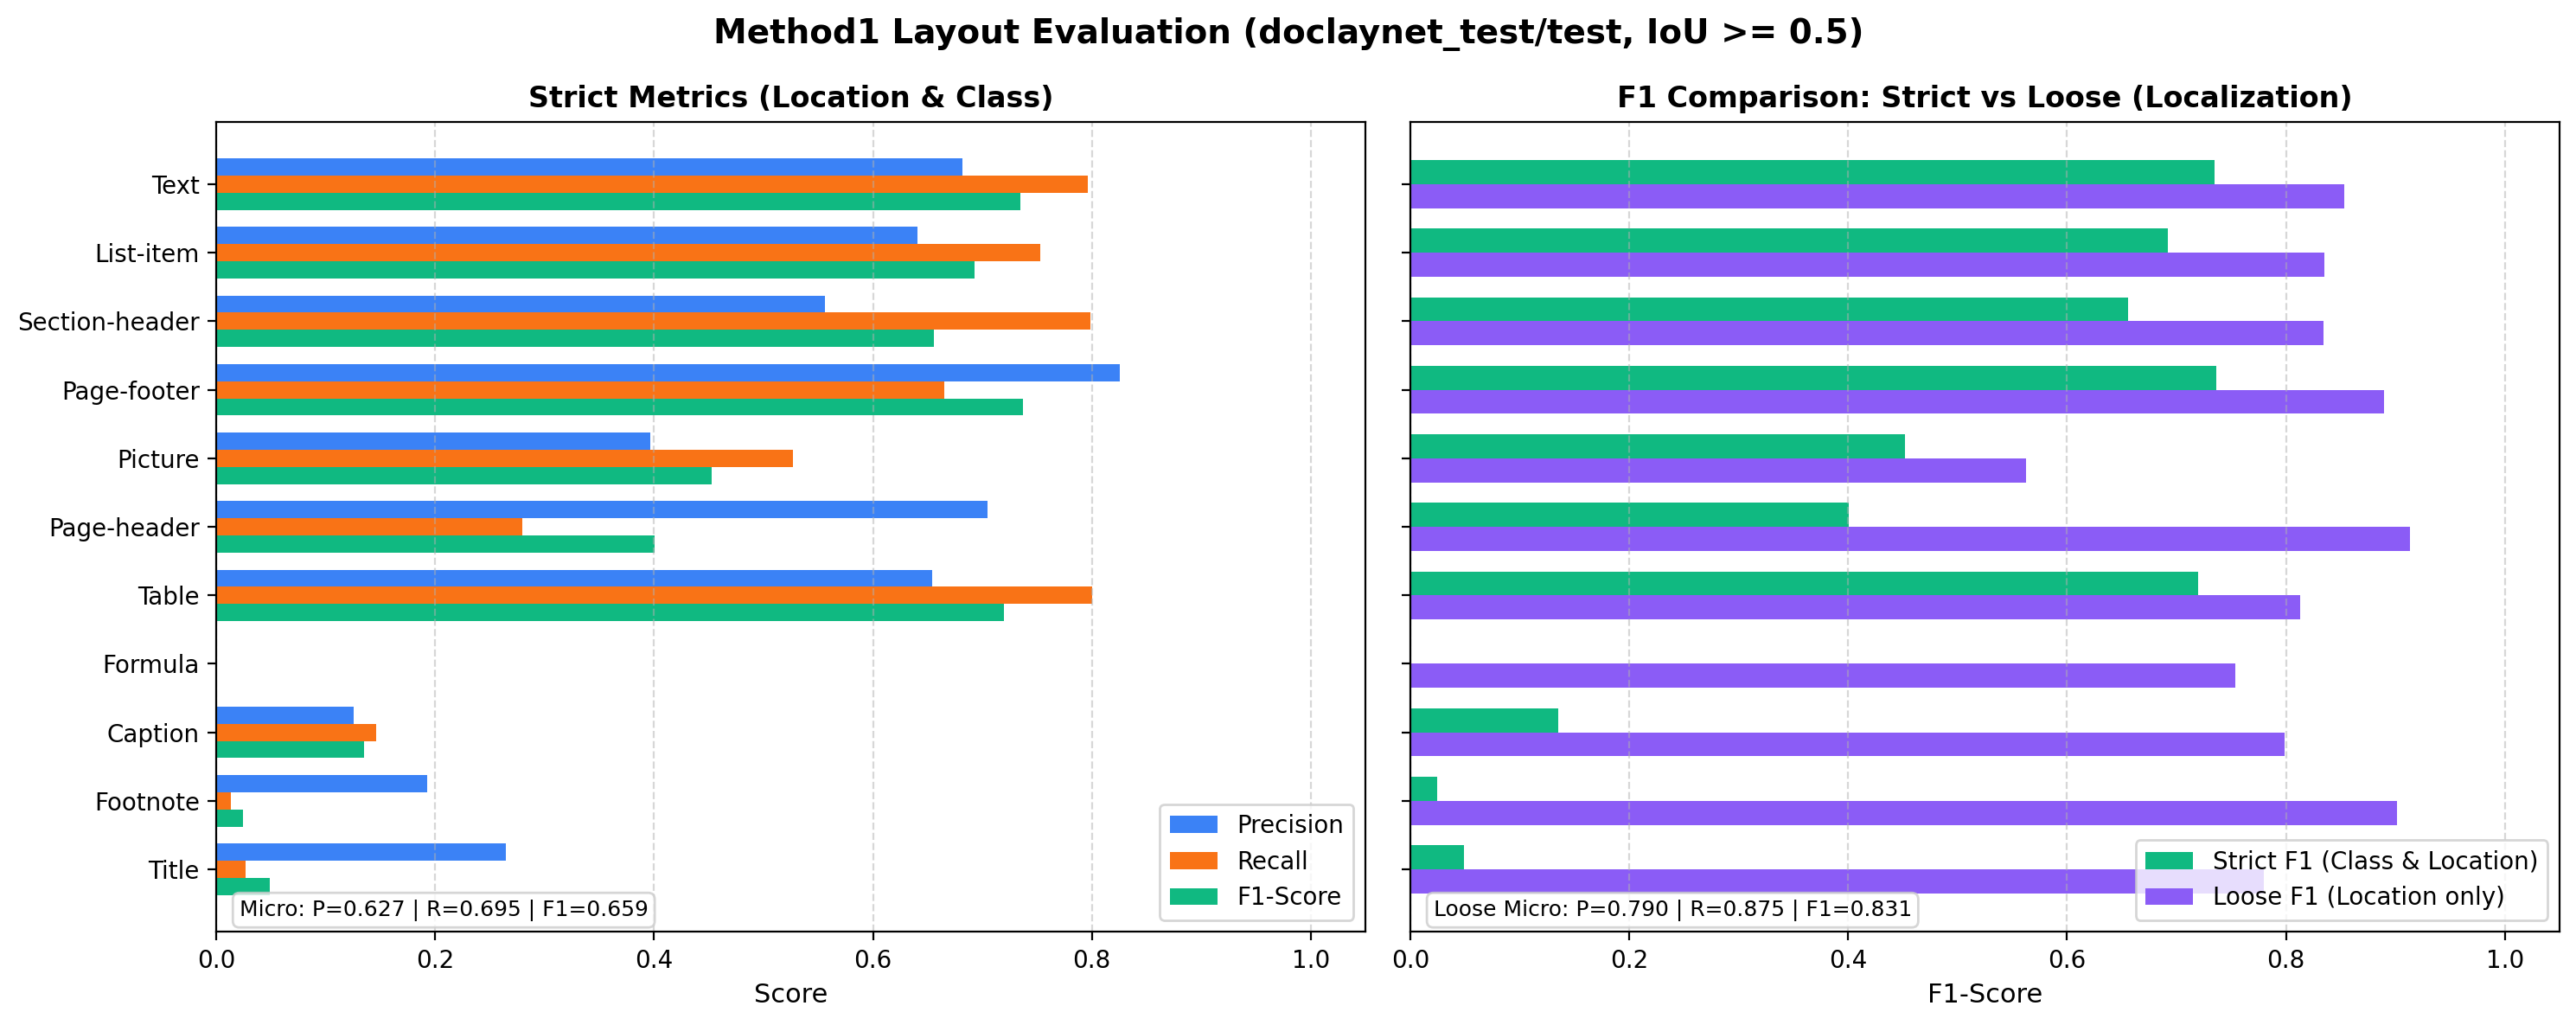

In [16]:
evaluation_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_file = FIGURES_DIR / "metrics_chart.png"

command = [
    sys.executable,
    str(evaluation_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--plot", str(chart_file),
]
if LIMIT > 0:
    command.append("--allow-incomplete")

print("Running evaluation:", " ".join(command))
env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
proc = subprocess.Popen(
    command,
    cwd=str(ROOT),
    env=env,
    text=True,
    encoding="utf-8",
    errors="replace",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

for line in proc.stdout:
    print(line, end="", flush=True)

if proc.wait() != 0:
    raise RuntimeError(f"Đánh giá thất bại (exit code {proc.returncode}).")

# Hiển thị trực tiếp biểu đồ độ đo tổng thể
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"\nBiểu đồ đánh giá tổng thể ({chart_file.name}):")
    display(DisplayImage(filename=str(chart_file)))

## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu nhãn thực tế (**Ground Truth**) và kết quả dự đoán của mô hình (**Method 1**) cho `FIGURE_LIMIT` ảnh đầu của split.
Sử dụng script dùng chung của dự án (`visualization/scripts/visualize_predictions.py`):
* Hệ màu chuẩn 11 classes DocLayNet.
* Nhãn hiển thị dạng pill badge tránh đè chữ.
* Ghép 2 khung hình song song (Side-by-side): `[Ground Truth] | [Method 1 Prediction]`.

In [ ]:
visualizer = ROOT / "visualization" / "scripts" / "visualize_predictions.py"

command = [
    sys.executable,
    str(visualizer),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]

print("Running visualization:", " ".join(command))
env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
proc = subprocess.Popen(
    command,
    cwd=str(ROOT),
    env=env,
    text=True,
    encoding="utf-8",
    errors="replace",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

for line in proc.stdout:
    print(line, end="", flush=True)

if proc.wait() != 0:
    raise RuntimeError(f"Visualization thất bại (exit code {proc.returncode}).")

figure_files = sorted(
    FIGURES_DIR.glob("*.png"),
    key=lambda path: (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem),
)
example_figures = [f for f in figure_files if f.name != "metrics_chart.png"]

if example_figures:
    from IPython.display import Image as DisplayImage, display
    print(f"\nHiển thị các ví dụ đối chiếu trực quan Ground Truth vs Dự đoán Method 1 ({len(example_figures)} ảnh đã sinh):")
    for fig_path in example_figures[:3]:
        print(f"• Trang {fig_path.name}:", flush=True)
        display(DisplayImage(filename=str(fig_path)))
else:
    print(f"Không có hình ảnh đối chiếu nào trong {FIGURES_DIR}")

## Files đầu ra và báo cáo

- **Predictions JSON**: `outputs/predictions/method1/doclaynet_test/<image_id>.json`
- **Biểu đồ đánh giá**: `outputs/reports/method1_doclaynet_test/metrics_chart.png`
- **Ảnh đối chiếu trực quan**: `outputs/reports/method1_doclaynet_test/<image_id>.png`
- **Ground Truth COCO**: `datasets/doclaynet_test/processed/annotations/test.json`
- **Runtime Summary**: `outputs/runtime/method1/doclaynet_test.json`
- **Trọng số Detector**: `methods/method1/weights/yolov8n_doclaynet_10k_best.pt`
- **Trọng số Classifier**: `methods/method1/weights/pipeline_b_transformer_10k_best.pth`